# 06 · MLP: perceptrón multicapa en las dos tareas

**Proyecto:** Predicción del riesgo y la gravedad de accidentes en carreteras del Perú con datos abiertos y clima
(IA Aplicada 1INF62, PUCP 2026-2). **Issue #10** (MLP) e **issue #13** (ensamble por votación, §4). Respaldo: Emu et al. (2022), que usan redes neuronales
para predecir la fatalidad de un choque (paper 4 del README).

Este notebook prueba un **MLP** (perceptrón multicapa de scikit-learn) en las mismas tareas, con los mismos datos,
variables, validación y métricas que el baseline (`02_modelos.ipynb`), para que los números sean comparables:

| Tarea | MLP | Se compara con | Métrica principal |
|---|---|---|---|
| 1 · `N_ACC` | `MLPRegressor` con **pérdida de Poisson** (salida exponencial, como la regresión de Poisson) | Ingenuo media 28 días y Poisson | D² de Poisson |
| 1 · `HAY_FATAL` | `MLPClassifier` sin pesos de clase (probabilidades calibradas, igual que la logística del baseline) | Ingenuo fatales 28 días y logística | PR-AUC |
| 2 · `GRAVEDAD` | `MLPClassifier` con **pesos de clase balanceados** (`M.PesosBalanceados`, el equivalente a `class_weight="balanced"` de la logística) | Dummy, Modelo 2 del avance y logística multinomial | Macro-F1 |

**Entrada:** el mismo `M.preprocesador` del modelo lineal (numéricas estandarizadas, ordinales y one-hot): 43 columnas en
la Tarea 1 y 67 en la Tarea 2. La red necesita las variables en la misma escala, así que no se usa el de árboles.

**Ajuste de hiperparámetros** (búsqueda en grilla, `GridSearchCV`): tamaño de las capas ocultas, regularización L2
(`alpha`) y número de épocas (`max_iter`). No se usa el early stopping de scikit-learn: separa una validación
**aleatoria** (en la Tarea 1 mezclaría días futuros y pasados) y, en clasificación, decide con la exactitud, que no
sirve con clases desbalanceadas. Las épocas se eligen como un hiperparámetro más, con la validación de cada tarea:
- **Tarea 1:** los mismos 5 pliegues de origen móvil sobre el train (`E.cv_temporal`). El holdout abr–sep 2021 solo
  se usa al final, una vez, con la configuración elegida.
- **Tarea 2:** `E.CV` (5 pliegues) **solo sobre el 80 % de entrenamiento**, así que el test 80/20 no se mira al ajustar.
  La comparación final usa la CV 5 × 5 (`E.CV_REPETIDA`), los mismos 25 pliegues del baseline.

In [1]:
import sys, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.metrics import ConfusionMatrixDisplay, PrecisionRecallDisplay, classification_report

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src import models as M, evaluation as E

warnings.filterwarnings("ignore")
PLOTS = ROOT / "results" / "plots"
PLOTS.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
FILAS = []   # filas nuevas de results/metrics.csv (solo las del MLP; las referencias ya están del baseline)
SEMILLAS = [42, 7, 123, 2024, 31]   # para medir cuánto cambia el MLP con la inicialización de los pesos


def guardar(fig, nombre):
    fig.savefig(PLOTS / nombre, bbox_inches="tight")
    plt.show()


def resumen(res):
    # media y desviación estándar por modelo (columnas: métrica, estadístico)
    return pd.DataFrame({k: v.agg(["mean", "std"]).T.stack() for k, v in res.items()}).T.round(4)


def ajustar(modelo, grilla, X, y, cv, scoring):
    """Búsqueda en grilla. Devuelve el modelo con la mejor configuración (sin reentrenar) y las 5 mejores filas."""
    t = time.time()
    gs = GridSearchCV(modelo, grilla, scoring=scoring, cv=cv, n_jobs=-1, refit=False).fit(X, y)
    tabla = pd.DataFrame(gs.cv_results_)
    tabla = tabla.sort_values("rank_test_score")[["params", "mean_test_score", "std_test_score"]].head(5)
    tabla["params"] = tabla.params.map(lambda p: ", ".join(f"{k.split('__')[-1]}={v}" for k, v in p.items()))
    print(f"{len(gs.cv_results_['params'])} configuraciones en {time.time() - t:.0f} s · mejor: {gs.best_params_}")
    display(tabla.round(4))
    return clone(modelo).set_params(**gs.best_params_), gs.best_params_


def config(params):
    return ", ".join(f"{k.split('__')[-1]}={v}" for k, v in params.items())

## 1. Tarea 1 · Pronóstico de riesgo (panel departamento × día)
Mismo panel, mismo corte (train hasta marzo de 2021, holdout abril–septiembre de 2021) y mismos pliegues que el baseline.

In [2]:
panel = M.cargar_panel()
tr1 = panel[panel.FECHA < M.INICIO_HOLDOUT].reset_index(drop=True)
te1 = panel[panel.FECHA >= M.INICIO_HOLDOUT].reset_index(drop=True)
COLS1 = M.columnas(M.GRUPOS_T1)
X1 = COLS1[0] + COLS1[1]
FOLDS1 = list(E.cv_temporal(tr1.FECHA))
print(f"Train: {len(tr1):,} filas · holdout: {len(te1):,} filas · {M.n_columnas(COLS1, tr1)} columnas tras el encoding")

Train: 10,776 filas · holdout: 4,392 filas · 43 columnas tras el encoding


### 1.1 Conteo de accidentes (`N_ACC`)
Grilla: capas ocultas (16), (32), (32, 16), (64, 32); `alpha` 0.1, 1, 10; épocas 20, 50, 150. Criterio: devianza de
Poisson media en los 5 pliegues temporales (equivale a ordenar por D²).

In [3]:
grilla = {"reg__hidden_layer_sizes": [(16,), (32,), (32, 16), (64, 32)],
          "reg__alpha": [0.1, 1.0, 10.0],
          "reg__max_iter": [20, 50, 150]}
mlp1, P1 = ajustar(M.mlp_conteo(COLS1), grilla, tr1[X1], tr1.N_ACC, FOLDS1, "neg_mean_poisson_deviance")

36 configuraciones en 22 s · mejor: {'reg__alpha': 1.0, 'reg__hidden_layer_sizes': (32, 16), 'reg__max_iter': 50}


,params,mean_test_score,std_test_score
19,"alpha=1.0, hidden_layer_sizes=(32, 16), max_it...",-0.9588,0.0604
16,"alpha=1.0, hidden_layer_sizes=(32,), max_iter=50",-0.9589,0.0588
4,"alpha=0.1, hidden_layer_sizes=(32,), max_iter=50",-0.9598,0.0675
18,"alpha=1.0, hidden_layer_sizes=(32, 16), max_it...",-0.9600,0.0612
22,"alpha=1.0, hidden_layer_sizes=(64, 32), max_it...",-0.9616,0.0519


In [4]:
ingenuo_conteo = lambda df, col: df[col].fillna(df.N_ACC_M7)
res1 = {"Ingenuo · media 28 días": pd.DataFrame([E.metricas_conteo(tr1.N_ACC.iloc[b], ingenuo_conteo(tr1.iloc[b], "N_ACC_M28")) for _, b in FOLDS1]),
        "Baseline · Poisson": E.cv_puntajes(M.poisson(COLS1), tr1[X1], tr1.N_ACC, FOLDS1, E.metricas_conteo),
        "MLP (ajustado)": E.cv_puntajes(mlp1, tr1[X1], tr1.N_ACC, FOLDS1, E.metricas_conteo)}
display(resumen(res1))
print("MLP − Poisson (D²):        ", E.comparacion_pareada(res1["MLP (ajustado)"].d2_poisson, res1["Baseline · Poisson"].d2_poisson))
print("MLP − media 28 días (D²):  ", E.comparacion_pareada(res1["MLP (ajustado)"].d2_poisson, res1["Ingenuo · media 28 días"].d2_poisson))
print("Nota: la configuración se eligió con estos mismos pliegues, así que el CV del MLP es algo optimista; el holdout no.")

pred_pois = clone(M.poisson(COLS1)).fit(tr1[X1], tr1.N_ACC).predict(te1[X1])
pred_mlp1 = clone(mlp1).fit(tr1[X1], tr1.N_ACC).predict(te1[X1])
hold1 = {"Ingenuo · media 28 días": E.metricas_conteo(te1.N_ACC, ingenuo_conteo(te1, "N_ACC_M28")),
         "Baseline · Poisson": E.metricas_conteo(te1.N_ACC, pred_pois),
         "MLP (ajustado)": E.metricas_conteo(te1.N_ACC, pred_mlp1)}
display(pd.DataFrame(hold1).T.round(4))
FILAS.append({"tarea": "1_conteo_N_ACC", "modelo": "MLP (ajustado)", "validacion": "CV temporal (5 pliegues)", **res1["MLP (ajustado)"].mean().to_dict()})
FILAS.append({"tarea": "1_conteo_N_ACC", "modelo": "MLP (ajustado)", "validacion": "holdout abr-sep 2021", **hold1["MLP (ajustado)"]})

poisson_dev         d2_poisson             mae  \
                               mean     std       mean     std    mean   
Ingenuo · media 28 días      0.9984  0.0469     0.2173  0.0525  0.5464   
Baseline · Poisson           0.9489  0.0529     0.2562  0.0535  0.5685   
MLP (ajustado)               0.9588  0.0676     0.2499  0.0329  0.5626   

                                   rmse          
                            std    mean     std  
Ingenuo · media 28 días  0.0623  0.7892  0.0802  
Baseline · Poisson       0.0339  0.7923  0.0584  
MLP (ajustado)           0.0550  0.7929  0.0745

MLP − Poisson (D²):         -0.006 (IC95% aprox. -0.032 a +0.019), mejor en 1 de 5 pliegues
MLP − media 28 días (D²):   +0.033 (IC95% aprox. +0.011 a +0.054), mejor en 5 de 5 pliegues
Nota: la configuración se eligió con estos mismos pliegues, así que el CV del MLP es algo optimista; el holdout no.


,poisson_dev,d2_poisson,mae,rmse
Ingenuo · media 28 días,1.0019,0.2775,0.6046,0.8365
Baseline · Poisson,1.0170,0.2665,0.5896,0.8504
MLP (ajustado),0.9816,0.2921,0.6061,0.8345


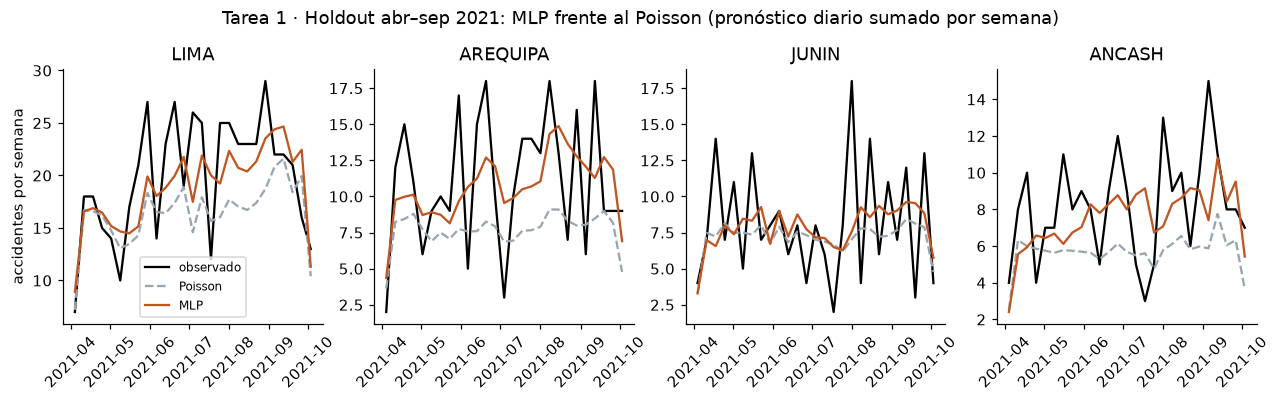

In [5]:
top = panel.groupby("DEPARTAMENTO").N_ACC.sum().nlargest(4).index
sem = te1.assign(POIS=pred_pois, MLP=pred_mlp1).groupby(["DEPARTAMENTO", pd.Grouper(key="FECHA", freq="W")])[["N_ACC", "POIS", "MLP"]].sum()
fig, axs = plt.subplots(1, 4, figsize=(14, 3))
for ax, d in zip(axs, top):
    s = sem.loc[d]
    ax.plot(s.index, s.N_ACC, "k-", lw=1.5, label="observado")
    ax.plot(s.index, s.POIS, "--", color="#9aa5b1", label="Poisson")
    ax.plot(s.index, s.MLP, "-", color="#c05621", label="MLP")
    ax.set_title(d); ax.tick_params(axis="x", rotation=45)
axs[0].set_ylabel("accidentes por semana"); axs[0].legend(fontsize=8)
fig.suptitle("Tarea 1 · Holdout abr–sep 2021: MLP frente al Poisson (pronóstico diario sumado por semana)", y=1.06)
guardar(fig, "modelo_10_t1_conteo_mlp_holdout.png")

### 1.2 ¿Habrá algún accidente fatal mañana? (`HAY_FATAL`)
MLP sin pesos de clase, como la logística del baseline, para que las probabilidades queden calibradas (Brier).
Grilla: capas (8), (16), (32); `alpha` 1, 10, 30; épocas 50, 150, 300. Criterio: PR-AUC media en los pliegues temporales.

In [6]:
grilla = {"clf__hidden_layer_sizes": [(8,), (16,), (32,)],
          "clf__alpha": [1.0, 10.0, 30.0],
          "clf__max_iter": [50, 150, 300]}
mlp1b, P1b = ajustar(M.mlp_clasificador(COLS1, balanceado=False), grilla, tr1[X1], tr1.HAY_FATAL, FOLDS1, "average_precision")

27 configuraciones en 13 s · mejor: {'clf__alpha': 1.0, 'clf__hidden_layer_sizes': (8,), 'clf__max_iter': 150}


,params,mean_test_score,std_test_score
1,"alpha=1.0, hidden_layer_sizes=(8,), max_iter=150",0.1378,0.0159
2,"alpha=1.0, hidden_layer_sizes=(8,), max_iter=300",0.1375,0.0151
20,"alpha=30.0, hidden_layer_sizes=(8,), max_iter=300",0.1365,0.0162
23,"alpha=30.0, hidden_layer_sizes=(16,), max_iter...",0.1363,0.0162
26,"alpha=30.0, hidden_layer_sizes=(32,), max_iter...",0.1363,0.0162


pr_auc         roc_auc           brier  \
                                     mean     std    mean     std    mean   
Ingenuo · fatales últimos 28 días  0.1119  0.0178  0.6775  0.0140  0.0542   
Baseline · Reg. logística          0.1330  0.0279  0.7041  0.0254  0.0561   
MLP (ajustado)                     0.1378  0.0178  0.6994  0.0154  0.0542   

                                          prevalencia          
                                      std        mean     std  
Ingenuo · fatales últimos 28 días  0.0067      0.0584  0.0081  
Baseline · Reg. logística          0.0076      0.0584  0.0081  
MLP (ajustado)                     0.0065      0.0584  0.0081

MLP − logística (PR-AUC):   +0.005 (IC95% aprox. -0.027 a +0.036), mejor en 1 de 5 pliegues
MLP − ingenuo (PR-AUC):     +0.026 (IC95% aprox. +0.018 a +0.034), mejor en 5 de 5 pliegues


,pr_auc,roc_auc,brier,prevalencia
Ingenuo · fatales últimos 28 días,0.1313,0.6887,0.0618,0.0676
Baseline · Reg. logística,0.1612,0.7335,0.0600,0.0676
MLP (ajustado),0.1569,0.7223,0.0604,0.0676


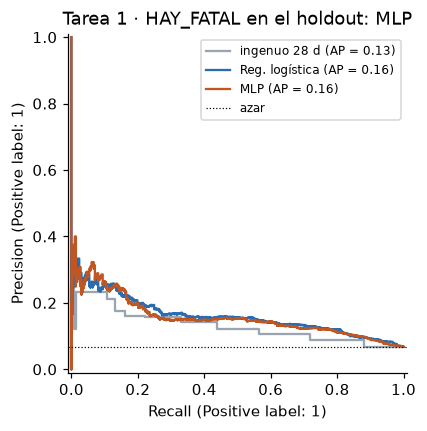

In [7]:
ingenuo_fatal = lambda df: 1 - np.exp(-df.N_FATALES_M28)
logit1 = M.logit(COLS1, class_weight=None)
res1b = {"Ingenuo · fatales últimos 28 días": pd.DataFrame([E.metricas_binaria(tr1.HAY_FATAL.iloc[b], ingenuo_fatal(tr1.iloc[b])) for _, b in FOLDS1]),
         "Baseline · Reg. logística": E.cv_puntajes(logit1, tr1[X1], tr1.HAY_FATAL, FOLDS1, E.metricas_binaria, proba=True),
         "MLP (ajustado)": E.cv_puntajes(mlp1b, tr1[X1], tr1.HAY_FATAL, FOLDS1, E.metricas_binaria, proba=True)}
display(resumen(res1b))
print("MLP − logística (PR-AUC):  ", E.comparacion_pareada(res1b["MLP (ajustado)"].pr_auc, res1b["Baseline · Reg. logística"].pr_auc))
print("MLP − ingenuo (PR-AUC):    ", E.comparacion_pareada(res1b["MLP (ajustado)"].pr_auc, res1b["Ingenuo · fatales últimos 28 días"].pr_auc))

prob_log = clone(logit1).fit(tr1[X1], tr1.HAY_FATAL).predict_proba(te1[X1])[:, 1]
prob_mlp1b = clone(mlp1b).fit(tr1[X1], tr1.HAY_FATAL).predict_proba(te1[X1])[:, 1]
hold1b = {"Ingenuo · fatales últimos 28 días": E.metricas_binaria(te1.HAY_FATAL, ingenuo_fatal(te1)),
          "Baseline · Reg. logística": E.metricas_binaria(te1.HAY_FATAL, prob_log),
          "MLP (ajustado)": E.metricas_binaria(te1.HAY_FATAL, prob_mlp1b)}
display(pd.DataFrame(hold1b).T.round(4))
FILAS.append({"tarea": "1_clasificacion_HAY_FATAL", "modelo": "MLP (ajustado)", "validacion": "CV temporal (5 pliegues)", **res1b["MLP (ajustado)"].mean().to_dict()})
FILAS.append({"tarea": "1_clasificacion_HAY_FATAL", "modelo": "MLP (ajustado)", "validacion": "holdout abr-sep 2021", **hold1b["MLP (ajustado)"]})

fig, ax = plt.subplots(figsize=(5.5, 4))
PrecisionRecallDisplay.from_predictions(te1.HAY_FATAL, ingenuo_fatal(te1), name="ingenuo 28 d", ax=ax, color="#9aa5b1")
PrecisionRecallDisplay.from_predictions(te1.HAY_FATAL, prob_log, name="Reg. logística", ax=ax, color="#2b6cb0")
PrecisionRecallDisplay.from_predictions(te1.HAY_FATAL, prob_mlp1b, name="MLP", ax=ax, color="#c05621")
ax.axhline(te1.HAY_FATAL.mean(), color="k", ls=":", lw=0.8, label="azar")
ax.set_title("Tarea 1 · HAY_FATAL en el holdout: MLP"); ax.legend(fontsize=8)
guardar(fig, "modelo_11_t1_hay_fatal_mlp_holdout.png")

## 2. Tarea 2 · Triaje de gravedad al recibir el reporte
Mismo dataset, mismas 67 columnas, mismos 25 pliegues de la CV 5 × 5 y mismo test 80/20 (`random_state=42`).
La grilla se evalúa con `E.CV` **solo dentro del 80 % de entrenamiento**. Criterio: macro-F1.

In [8]:
acc = M.cargar_accidentes()
COLS2 = M.columnas(M.GRUPOS_T2)
X2 = COLS2[0] + COLS2[1]
y2 = acc.GRAVEDAD
tr2, te2 = train_test_split(acc, test_size=0.2, stratify=y2, random_state=M.SEED)
print(f"{len(acc):,} accidentes · {M.n_columnas(COLS2, acc)} columnas tras el encoding · train {len(tr2):,} / test {len(te2):,}")

grilla = {"clf__estimator__hidden_layer_sizes": [(32,), (64,), (128,), (64, 32)],
          "clf__estimator__alpha": [0.1, 1.0, 3.0],
          "clf__estimator__max_iter": [30, 100, 300]}
mlp2, P2 = ajustar(M.mlp_clasificador(COLS2), grilla, tr2[X2], tr2.GRAVEDAD, E.CV, "f1_macro")

8,105 accidentes · 67 columnas tras el encoding · train 6,484 / test 1,621


36 configuraciones en 48 s · mejor: {'clf__estimator__alpha': 0.1, 'clf__estimator__hidden_layer_sizes': (32,), 'clf__estimator__max_iter': 30}


,params,mean_test_score,std_test_score
0,"alpha=0.1, hidden_layer_sizes=(32,), max_iter=30",0.4180,0.0097
25,"alpha=3.0, hidden_layer_sizes=(32,), max_iter=100",0.4176,0.0125
19,"alpha=1.0, hidden_layer_sizes=(128,), max_iter...",0.4168,0.0138
7,"alpha=0.1, hidden_layer_sizes=(128,), max_iter...",0.4165,0.0100
17,"alpha=1.0, hidden_layer_sizes=(64,), max_iter=300",0.4164,0.0139


In [9]:
FOLDS2 = list(E.CV_REPETIDA.split(acc[X2], y2))
modelo2_avance = M.logit((["ELEVACION", "HORA_SIN", "HORA_COS"], ["DEPARTAMENTO", "MODALIDAD"]))
base2 = M.logit(COLS2)
res2 = {"Dummy (proporciones)": E.cv_puntajes(DummyClassifier(strategy="prior"), acc[X2], y2, FOLDS2, E.metricas_multiclase, proba=True),
        "Modelo 2 del avance (4 variables)": E.cv_puntajes(modelo2_avance, acc[X2], y2, FOLDS2, E.metricas_multiclase, proba=True),
        "Baseline · Reg. logística multinomial": E.cv_puntajes(base2, acc[X2], y2, FOLDS2, E.metricas_multiclase, proba=True),
        "MLP (ajustado)": E.cv_puntajes(mlp2, acc[X2], y2, FOLDS2, E.metricas_multiclase, proba=True)}
display(resumen(res2))
for met, mayor in (("macro_f1", True), ("balanced_acc", True), ("pr_auc_fatal", True), ("log_loss", False)):
    print(f"MLP − logística multinomial ({met}):",
          E.comparacion_pareada(res2["MLP (ajustado)"][met], res2["Baseline · Reg. logística multinomial"][met], mayor_es_mejor=mayor))
FILAS.append({"tarea": "2_triaje_GRAVEDAD", "modelo": "MLP (ajustado)", "validacion": "CV estratificada 5x5", **res2["MLP (ajustado)"].mean().to_dict()})

macro_f1         balanced_acc          \
                                          mean     std         mean     std   
Dummy (proporciones)                    0.2278  0.0001       0.3333  0.0000   
Modelo 2 del avance (4 variables)       0.4213  0.0095       0.4690  0.0119   
Baseline · Reg. logística multinomial   0.4190  0.0078       0.4656  0.0096   
MLP (ajustado)                          0.4218  0.0117       0.4603  0.0125   

                                      pr_auc_fatal         log_loss          
                                              mean     std     mean     std  
Dummy (proporciones)                        0.1173  0.0003   0.9596  0.0003  
Modelo 2 del avance (4 variables)           0.2694  0.0256   1.0372  0.0069  
Baseline · Reg. logística multinomial       0.2655  0.0269   1.0371  0.0088  
MLP (ajustado)                              0.2542  0.0219   1.0391  0.0125

MLP − logística multinomial (macro_f1): +0.003 (IC95% aprox. -0.001 a +0.006), mejor en 16 de 25 pliegues
MLP − logística multinomial (balanced_acc): -0.005 (IC95% aprox. -0.009 a -0.001), mejor en 8 de 25 pliegues
MLP − logística multinomial (pr_auc_fatal): -0.011 (IC95% aprox. -0.016 a -0.006), mejor en 4 de 25 pliegues
MLP − logística multinomial (log_loss): +0.002 (IC95% aprox. -0.001 a +0.005), mejor en 10 de 25 pliegues


### 2.1 Test 80/20: matriz de confusión

,macro_f1,balanced_acc,pr_auc_fatal,log_loss
Baseline · Reg. logística multinomial,0.4360,0.4836,0.2597,1.0191
MLP (ajustado),0.4299,0.4710,0.2451,1.0257


              precision    recall  f1-score   support

sin víctimas      0.492     0.520     0.506       590
     heridos      0.582     0.403     0.476       841
       fatal      0.224     0.489     0.307       190

    accuracy                          0.456      1621
   macro avg      0.433     0.471     0.430      1621
weighted avg      0.508     0.456     0.467      1621



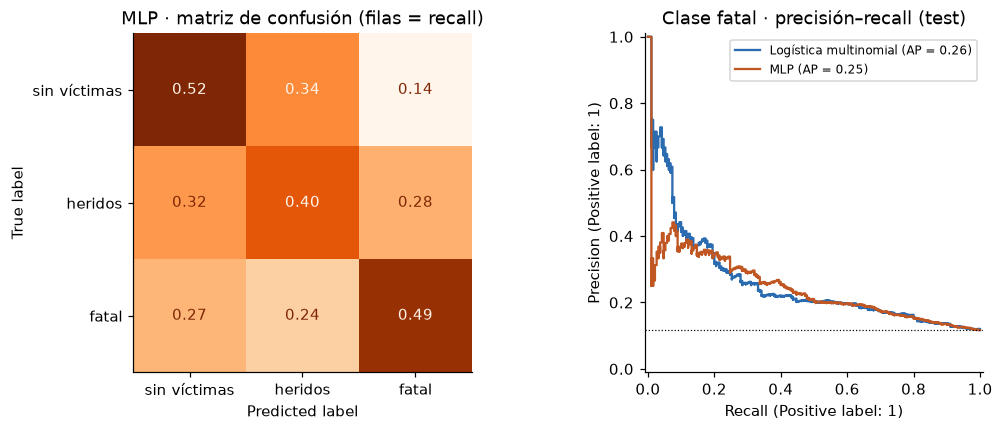

In [10]:
proba_log2 = clone(base2).fit(tr2[X2], tr2.GRAVEDAD).predict_proba(te2[X2])
proba_mlp2 = clone(mlp2).fit(tr2[X2], tr2.GRAVEDAD).predict_proba(te2[X2])
hold2 = {"Baseline · Reg. logística multinomial": E.metricas_multiclase(te2.GRAVEDAD, proba_log2),
         "MLP (ajustado)": E.metricas_multiclase(te2.GRAVEDAD, proba_mlp2)}
display(pd.DataFrame(hold2).T.round(4))
print(classification_report(te2.GRAVEDAD, proba_mlp2.argmax(1), target_names=M.CLASES_T2, digits=3))
FILAS.append({"tarea": "2_triaje_GRAVEDAD", "modelo": "MLP (ajustado)", "validacion": "test estratificado 80/20", **hold2["MLP (ajustado)"]})

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(te2.GRAVEDAD, proba_mlp2.argmax(1), display_labels=M.CLASES_T2, normalize="true",
                                        values_format=".2f", cmap="Oranges", ax=axs[0], colorbar=False)
axs[0].set_title("MLP · matriz de confusión (filas = recall)")
PrecisionRecallDisplay.from_predictions(te2.GRAVEDAD == 2, proba_log2[:, 2], name="Logística multinomial", ax=axs[1], color="#2b6cb0")
PrecisionRecallDisplay.from_predictions(te2.GRAVEDAD == 2, proba_mlp2[:, 2], name="MLP", ax=axs[1], color="#c05621")
axs[1].axhline((te2.GRAVEDAD == 2).mean(), color="k", ls=":", lw=0.8)
axs[1].set_title("Clase fatal · precisión–recall (test)"); axs[1].legend(fontsize=8)
guardar(fig, "modelo_12_t2_mlp_test.png")

## 3. Sensibilidad a la semilla
A diferencia de los modelos lineales, el resultado de un MLP depende de la inicialización aleatoria de los pesos. Se
reentrena la configuración elegida con 5 semillas y se evalúa en el holdout (Tarea 1) y en el test (Tarea 2). Si la
diferencia con el baseline es menor que esta variación, no se puede atribuir a la red.

In [11]:
def con_semilla(modelo, s):
    clave = [k for k in modelo.get_params() if k.endswith("random_state")][0]
    return clone(modelo).set_params(**{clave: s})

filas = []
for s in SEMILLAS:
    filas.append({"semilla": s,
                  "T1 D² holdout": E.metricas_conteo(te1.N_ACC, con_semilla(mlp1, s).fit(tr1[X1], tr1.N_ACC).predict(te1[X1]))["d2_poisson"],
                  "T1 PR-AUC holdout": E.metricas_binaria(te1.HAY_FATAL, con_semilla(mlp1b, s).fit(tr1[X1], tr1.HAY_FATAL).predict_proba(te1[X1])[:, 1])["pr_auc"],
                  "T2 macro-F1 test": E.metricas_multiclase(te2.GRAVEDAD, con_semilla(mlp2, s).fit(tr2[X2], tr2.GRAVEDAD).predict_proba(te2[X2]))["macro_f1"]})
semillas = pd.DataFrame(filas).set_index("semilla")
display(pd.concat([semillas, semillas.agg(["mean", "std", "min", "max"])]).round(4))
print("Baseline en las mismas particiones: "
      f"T1 D² {hold1['Baseline · Poisson']['d2_poisson']:.4f} · T1 PR-AUC {hold1b['Baseline · Reg. logística']['pr_auc']:.4f} · "
      f"T2 macro-F1 {hold2['Baseline · Reg. logística multinomial']['macro_f1']:.4f}")

,T1 D² holdout,T1 PR-AUC holdout,T2 macro-F1 test
42,0.2921,0.1569,0.4299
7,0.2808,0.1553,0.4270
123,0.2778,0.1580,0.4190
2024,0.2784,0.1597,0.4101
31,0.2849,0.1538,0.4297
mean,0.2828,0.1567,0.4231
std,0.0059,0.0023,0.0085
min,0.2778,0.1538,0.4101
max,0.2921,0.1597,0.4299


Baseline en las mismas particiones: T1 D² 0.2665 · T1 PR-AUC 0.1612 · T2 macro-F1 0.4360


## 4. Ensamble por votación (issue #13)
Respaldo: Emu et al. (2022), que combinan clasificadores por votación para tratar el desbalance de clases. Se combinan
los cuatro modelos del proyecto, **cada uno con la configuración que eligió su propia búsqueda** (no se vuelven a
ajustar aquí):

| Variable | Miembros | Combinación |
|---|---|---|
| `N_ACC` | Poisson (baseline), MLP, Random Forest y gradient boosting | promedio de los accidentes esperados |
| `HAY_FATAL` | logística, MLP, RF y GBM, **todos sin pesos de clase** | votación suave (promedio de probabilidades) |
| `GRAVEDAD` | logística, MLP, RF y GBM, **todos con pesos balanceados** | votación suave (promedio de probabilidades) |

Todos los miembros usan el mismo tratamiento de clases, así que sus probabilidades están en la misma escala y se pueden
promediar. Los pesos son iguales: el ensamble no tiene hiperparámetros propios, así que el holdout y el test no se
usan para elegir nada. Misma validación que el resto: pliegues temporales y holdout en la Tarea 1; CV 5 × 5 y test
80/20 en la Tarea 2. Cada ensamble se compara con su referencia, con el baseline y con el **mejor modelo individual**.
Como los miembros se ajustaron con estos mismos pliegues, el CV del ensamble es algo optimista; el holdout y el test no.

In [12]:
ENS = "Ensamble (votación)"
RF, GBM = "Random Forest (ajustado)", "Gradient boosting (ajustado)"
# Configuraciones elegidas en 03_random_forest.ipynb y 04_gradient_boosting.ipynb (salida de sus búsquedas).
RF_AJ = {"N_ACC": dict(min_samples_leaf=20, max_features=0.2, max_depth=20),
         "HAY_FATAL": dict(class_weight=None, min_samples_leaf=40, max_features=0.35, max_depth=8),
         "GRAVEDAD": dict(class_weight="balanced_subsample", min_samples_leaf=3, max_features="sqrt", max_depth=12)}
GBM_AJ = {"N_ACC": dict(learning_rate=0.03, max_iter=100, max_leaf_nodes=7, min_samples_leaf=100, l2_regularization=1.0),
          "HAY_FATAL": dict(class_weight=None, learning_rate=0.03, max_iter=150, max_leaf_nodes=7, min_samples_leaf=200,
                            l2_regularization=10.0),
          "GRAVEDAD": dict(learning_rate=0.03, max_iter=600, max_leaf_nodes=15, min_samples_leaf=20, l2_regularization=0.0)}

rf1, gbm1 = M.rf_conteo(COLS1, **RF_AJ["N_ACC"]), M.gbm_conteo(COLS1, **GBM_AJ["N_ACC"])
rf1b, gbm1b = M.random_forest(COLS1, **RF_AJ["HAY_FATAL"]), M.gbm_clasificador(COLS1, **GBM_AJ["HAY_FATAL"])
rf2, gbm2 = M.random_forest(COLS2, **RF_AJ["GRAVEDAD"]), M.gbm_clasificador(COLS2, **GBM_AJ["GRAVEDAD"])

ens1 = M.votacion([("poisson", M.poisson(COLS1)), ("mlp", mlp1), ("rf", rf1), ("gbm", gbm1)], conteo=True)
ens1b = M.votacion([("logistica", logit1), ("mlp", mlp1b), ("rf", rf1b), ("gbm", gbm1b)])
ens2 = M.votacion([("logistica", base2), ("mlp", mlp2), ("rf", rf2), ("gbm", gbm2)])
NOMBRES = {"poisson": "Baseline · Poisson", "logistica": "Baseline · Reg. logística", "mlp": "MLP (ajustado)", "rf": RF, "gbm": GBM}


def mejor_individual(res, metrica, candidatos, mayor_es_mejor=True):
    medias = pd.Series({k: res[k][metrica].mean() for k in candidatos})
    return medias.idxmax() if mayor_es_mejor else medias.idxmin()


def correlaciones(ens_ajustado, X, col=None):
    # Correlación entre las predicciones de los miembros: cuanto menor, más puede aportar promediarlos.
    pred = {}
    for k, m in ens_ajustado.named_estimators_.items():
        pred[NOMBRES[k]] = m.predict(X) if col is None else m.predict_proba(X)[:, col]
    return pd.DataFrame(pred)

### 4.1 `N_ACC`: promedio de Poisson, MLP, RF y GBM

In [13]:
t = time.time()
r1 = {k: res1[k] for k in ("Ingenuo · media 28 días", "Baseline · Poisson", "MLP (ajustado)")}
r1[RF] = E.cv_puntajes(rf1, tr1[X1], tr1.N_ACC, FOLDS1, E.metricas_conteo)
r1[GBM] = E.cv_puntajes(gbm1, tr1[X1], tr1.N_ACC, FOLDS1, E.metricas_conteo)
r1[ENS] = E.cv_puntajes(ens1, tr1[X1], tr1.N_ACC, FOLDS1, E.metricas_conteo)
print(f"CV en {time.time() - t:.0f} s")
display(resumen(r1))
mejor1 = mejor_individual(r1, "d2_poisson", ["Baseline · Poisson", "MLP (ajustado)", RF, GBM])
print(f"Ensamble − Poisson (D²):        ", E.comparacion_pareada(r1[ENS].d2_poisson, r1["Baseline · Poisson"].d2_poisson))
print(f"Ensamble − media 28 días (D²):  ", E.comparacion_pareada(r1[ENS].d2_poisson, r1["Ingenuo · media 28 días"].d2_poisson))
print(f"Ensamble − {mejor1} (D²):", E.comparacion_pareada(r1[ENS].d2_poisson, r1[mejor1].d2_poisson))

ens1_fit = clone(ens1).fit(tr1[X1], tr1.N_ACC)
pred_ens1 = ens1_fit.predict(te1[X1])
pred_miembros1 = correlaciones(ens1_fit, te1[X1])
h1 = {"Ingenuo · media 28 días": E.metricas_conteo(te1.N_ACC, ingenuo_conteo(te1, "N_ACC_M28"))}
h1 |= {k: E.metricas_conteo(te1.N_ACC, v) for k, v in pred_miembros1.items()}
h1[ENS] = E.metricas_conteo(te1.N_ACC, pred_ens1)
display(pd.DataFrame(h1).T.round(4))
print("Correlación entre los miembros en el holdout:")
display(pred_miembros1.corr().round(3))
FILAS.append({"tarea": "1_conteo_N_ACC", "modelo": ENS, "validacion": "CV temporal (5 pliegues)", **r1[ENS].mean().to_dict()})
FILAS.append({"tarea": "1_conteo_N_ACC", "modelo": ENS, "validacion": "holdout abr-sep 2021", **h1[ENS]})

CV en 12 s


poisson_dev         d2_poisson             mae  \
                                    mean     std       mean     std    mean   
Ingenuo · media 28 días           0.9984  0.0469     0.2173  0.0525  0.5464   
Baseline · Poisson                0.9489  0.0529     0.2562  0.0535  0.5685   
MLP (ajustado)                    0.9588  0.0676     0.2499  0.0329  0.5626   
Random Forest (ajustado)          0.9537  0.0743     0.2544  0.0285  0.5662   
Gradient boosting (ajustado)      0.9374  0.0701     0.2668  0.0333  0.5593   
Ensamble (votación)               0.9364  0.0711     0.2678  0.0319  0.5608   

                                        rmse          
                                 std    mean     std  
Ingenuo · media 28 días       0.0623  0.7892  0.0802  
Baseline · Poisson            0.0339  0.7923  0.0584  
MLP (ajustado)                0.0550  0.7929  0.0745  
Random Forest (ajustado)      0.0569  0.7880  0.0825  
Gradient boosting (ajustado)  0.0475  0.7813  0.0785  
Ensamble (votación)           0.0493  0.7801  0.0784

Ensamble − Poisson (D²):         +0.012 (IC95% aprox. -0.014 a +0.037), mejor en 3 de 5 pliegues
Ensamble − media 28 días (D²):   +0.050 (IC95% aprox. +0.026 a +0.074), mejor en 5 de 5 pliegues
Ensamble − Gradient boosting (ajustado) (D²): +0.001 (IC95% aprox. -0.001 a +0.003), mejor en 3 de 5 pliegues


,poisson_dev,d2_poisson,mae,rmse
Ingenuo · media 28 días,1.0019,0.2775,0.6046,0.8365
Baseline · Poisson,1.0170,0.2665,0.5896,0.8504
MLP (ajustado),0.9816,0.2921,0.6061,0.8345
Random Forest (ajustado),0.9799,0.2933,0.6093,0.8366
Gradient boosting (ajustado),0.9857,0.2892,0.6020,0.8457
Ensamble (votación),0.9758,0.2963,0.6000,0.8355


Correlación entre los miembros en el holdout:


,Baseline · Poisson,MLP (ajustado),Random Forest (ajustado),Gradient boosting (ajustado)
Baseline · Poisson,1.000,0.968,0.966,0.973
MLP (ajustado),0.968,1.000,0.975,0.962
Random Forest (ajustado),0.966,0.975,1.000,0.982
Gradient boosting (ajustado),0.973,0.962,0.982,1.000


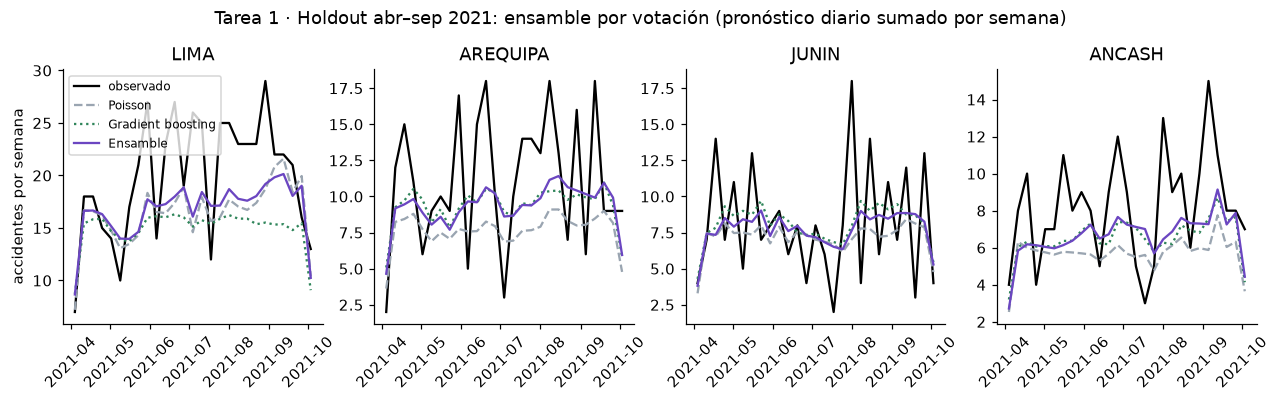

In [14]:
sem = te1.assign(POIS=pred_miembros1["Baseline · Poisson"], GBM=pred_miembros1[GBM], ENS=pred_ens1)
sem = sem.groupby(["DEPARTAMENTO", pd.Grouper(key="FECHA", freq="W")])[["N_ACC", "POIS", "GBM", "ENS"]].sum()
fig, axs = plt.subplots(1, 4, figsize=(14, 3))
for ax, d in zip(axs, top):
    s = sem.loc[d]
    ax.plot(s.index, s.N_ACC, "k-", lw=1.5, label="observado")
    ax.plot(s.index, s.POIS, "--", color="#9aa5b1", label="Poisson")
    ax.plot(s.index, s.GBM, ":", color="#2f855a", label="Gradient boosting")
    ax.plot(s.index, s.ENS, "-", color="#6b46c1", label="Ensamble")
    ax.set_title(d); ax.tick_params(axis="x", rotation=45)
axs[0].set_ylabel("accidentes por semana"); axs[0].legend(fontsize=8)
fig.suptitle("Tarea 1 · Holdout abr–sep 2021: ensamble por votación (pronóstico diario sumado por semana)", y=1.06)
guardar(fig, "modelo_16_t1_conteo_ensamble_holdout.png")

### 4.2 `HAY_FATAL`: votación suave de logística, MLP, RF y GBM (sin pesos de clase)

CV en 18 s


pr_auc         roc_auc           brier  \
                                     mean     std    mean     std    mean   
Ingenuo · fatales últimos 28 días  0.1119  0.0178  0.6775  0.0140  0.0542   
Baseline · Reg. logística          0.1330  0.0279  0.7041  0.0254  0.0561   
MLP (ajustado)                     0.1378  0.0178  0.6994  0.0154  0.0542   
Random Forest (ajustado)           0.1395  0.0189  0.7162  0.0123  0.0532   
Gradient boosting (ajustado)       0.1367  0.0156  0.7116  0.0160  0.0537   
Ensamble (votación)                0.1353  0.0184  0.7153  0.0127  0.0536   

                                          prevalencia          
                                      std        mean     std  
Ingenuo · fatales últimos 28 días  0.0067      0.0584  0.0081  
Baseline · Reg. logística          0.0076      0.0584  0.0081  
MLP (ajustado)                     0.0065      0.0584  0.0081  
Random Forest (ajustado)           0.0067      0.0584  0.0081  
Gradient boosting (ajustado)       0.0065      0.0584  0.0081  
Ensamble (votación)                0.0064      0.0584  0.0081

Ensamble − logística (PR-AUC):   +0.002 (IC95% aprox. -0.009 a +0.014), mejor en 2 de 5 pliegues
Ensamble − ingenuo (PR-AUC):     +0.023 (IC95% aprox. +0.003 a +0.044), mejor en 4 de 5 pliegues
Ensamble − Random Forest (ajustado) (PR-AUC): -0.004 (IC95% aprox. -0.020 a +0.011), mejor en 3 de 5 pliegues
Ensamble − logística (Brier):    -0.003 (IC95% aprox. -0.007 a +0.002), mejor en 4 de 5 pliegues


,pr_auc,roc_auc,brier,prevalencia
Ingenuo · fatales últimos 28 días,0.1313,0.6887,0.0618,0.0676
Baseline · Reg. logística,0.1612,0.7335,0.0600,0.0676
MLP (ajustado),0.1569,0.7223,0.0604,0.0676
Random Forest (ajustado),0.1583,0.7245,0.0602,0.0676
Gradient boosting (ajustado),0.1583,0.7349,0.0600,0.0676
Ensamble (votación),0.1600,0.7329,0.0600,0.0676


Correlación entre las probabilidades de los miembros en el holdout:


,Baseline · Reg. logística,MLP (ajustado),Random Forest (ajustado),Gradient boosting (ajustado)
Baseline · Reg. logística,1.000,0.932,0.912,0.964
MLP (ajustado),0.932,1.000,0.955,0.933
Random Forest (ajustado),0.912,0.955,1.000,0.935
Gradient boosting (ajustado),0.964,0.933,0.935,1.000


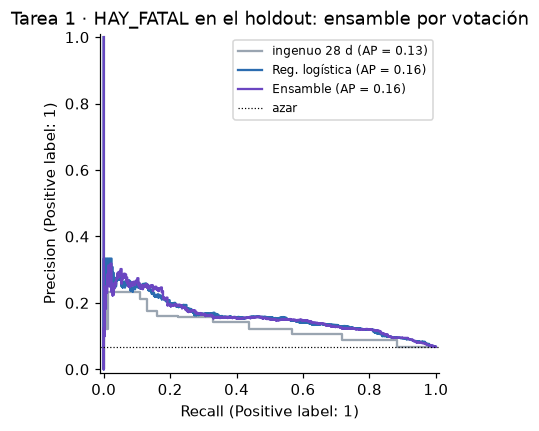

In [15]:
t = time.time()
r1b = {k: res1b[k] for k in ("Ingenuo · fatales últimos 28 días", "Baseline · Reg. logística", "MLP (ajustado)")}
r1b[RF] = E.cv_puntajes(rf1b, tr1[X1], tr1.HAY_FATAL, FOLDS1, E.metricas_binaria, proba=True)
r1b[GBM] = E.cv_puntajes(gbm1b, tr1[X1], tr1.HAY_FATAL, FOLDS1, E.metricas_binaria, proba=True)
r1b[ENS] = E.cv_puntajes(ens1b, tr1[X1], tr1.HAY_FATAL, FOLDS1, E.metricas_binaria, proba=True)
print(f"CV en {time.time() - t:.0f} s")
display(resumen(r1b))
mejor1b = mejor_individual(r1b, "pr_auc", ["Baseline · Reg. logística", "MLP (ajustado)", RF, GBM])
print(f"Ensamble − logística (PR-AUC):  ", E.comparacion_pareada(r1b[ENS].pr_auc, r1b["Baseline · Reg. logística"].pr_auc))
print(f"Ensamble − ingenuo (PR-AUC):    ", E.comparacion_pareada(r1b[ENS].pr_auc, r1b["Ingenuo · fatales últimos 28 días"].pr_auc))
print(f"Ensamble − {mejor1b} (PR-AUC):", E.comparacion_pareada(r1b[ENS].pr_auc, r1b[mejor1b].pr_auc))
print(f"Ensamble − logística (Brier):   ", E.comparacion_pareada(r1b[ENS].brier, r1b["Baseline · Reg. logística"].brier, mayor_es_mejor=False))

ens1b_fit = clone(ens1b).fit(tr1[X1], tr1.HAY_FATAL)
prob_ens1b = ens1b_fit.predict_proba(te1[X1])[:, 1]
prob_miembros1b = correlaciones(ens1b_fit, te1[X1], col=1)
h1b = {"Ingenuo · fatales últimos 28 días": E.metricas_binaria(te1.HAY_FATAL, ingenuo_fatal(te1))}
h1b |= {k: E.metricas_binaria(te1.HAY_FATAL, v) for k, v in prob_miembros1b.items()}
h1b[ENS] = E.metricas_binaria(te1.HAY_FATAL, prob_ens1b)
display(pd.DataFrame(h1b).T.round(4))
print("Correlación entre las probabilidades de los miembros en el holdout:")
display(prob_miembros1b.corr().round(3))
FILAS.append({"tarea": "1_clasificacion_HAY_FATAL", "modelo": ENS, "validacion": "CV temporal (5 pliegues)", **r1b[ENS].mean().to_dict()})
FILAS.append({"tarea": "1_clasificacion_HAY_FATAL", "modelo": ENS, "validacion": "holdout abr-sep 2021", **h1b[ENS]})

fig, ax = plt.subplots(figsize=(5.5, 4))
PrecisionRecallDisplay.from_predictions(te1.HAY_FATAL, ingenuo_fatal(te1), name="ingenuo 28 d", ax=ax, color="#9aa5b1")
PrecisionRecallDisplay.from_predictions(te1.HAY_FATAL, prob_miembros1b["Baseline · Reg. logística"], name="Reg. logística", ax=ax, color="#2b6cb0")
PrecisionRecallDisplay.from_predictions(te1.HAY_FATAL, prob_ens1b, name="Ensamble", ax=ax, color="#6b46c1")
ax.axhline(te1.HAY_FATAL.mean(), color="k", ls=":", lw=0.8, label="azar")
ax.set_title("Tarea 1 · HAY_FATAL en el holdout: ensamble por votación"); ax.legend(fontsize=8)
guardar(fig, "modelo_17_t1_hay_fatal_ensamble_holdout.png")

### 4.3 `GRAVEDAD`: votación suave de logística, MLP, RF y GBM (pesos balanceados)
La hipótesis de `04_gradient_boosting.ipynb`: los árboles ganan en macro-F1 (clases frecuentes) y la logística detecta
más fatales; el promedio de probabilidades podría juntar las dos fortalezas.

In [16]:
t = time.time()
r2 = {k: res2[k] for k in ("Dummy (proporciones)", "Baseline · Reg. logística multinomial", "MLP (ajustado)")}
r2[RF] = E.cv_puntajes(rf2, acc[X2], y2, FOLDS2, E.metricas_multiclase, proba=True)
r2[GBM] = E.cv_puntajes(gbm2, acc[X2], y2, FOLDS2, E.metricas_multiclase, proba=True)
r2[ENS] = E.cv_puntajes(ens2, acc[X2], y2, FOLDS2, E.metricas_multiclase, proba=True)
print(f"CV 5 × 5 en {time.time() - t:.0f} s")
display(resumen(r2))
mejor2 = mejor_individual(r2, "macro_f1", ["Baseline · Reg. logística multinomial", "MLP (ajustado)", RF, GBM])
for met, mayor in (("macro_f1", True), ("balanced_acc", True), ("pr_auc_fatal", True), ("log_loss", False)):
    print(f"Ensamble − logística multinomial ({met}):",
          E.comparacion_pareada(r2[ENS][met], r2["Baseline · Reg. logística multinomial"][met], mayor_es_mejor=mayor))
for met, mayor in (("macro_f1", True), ("pr_auc_fatal", True)):
    print(f"Ensamble − {mejor2} ({met}):", E.comparacion_pareada(r2[ENS][met], r2[mejor2][met], mayor_es_mejor=mayor))
FILAS.append({"tarea": "2_triaje_GRAVEDAD", "modelo": ENS, "validacion": "CV estratificada 5x5", **r2[ENS].mean().to_dict()})

CV 5 × 5 en 606 s


macro_f1         balanced_acc          \
                                          mean     std         mean     std   
Dummy (proporciones)                    0.2278  0.0001       0.3333  0.0000   
Baseline · Reg. logística multinomial   0.4190  0.0078       0.4656  0.0096   
MLP (ajustado)                          0.4218  0.0117       0.4603  0.0125   
Random Forest (ajustado)                0.4519  0.0103       0.4577  0.0106   
Gradient boosting (ajustado)            0.4331  0.0133       0.4420  0.0145   
Ensamble (votación)                     0.4466  0.0123       0.4662  0.0132   

                                      pr_auc_fatal         log_loss          
                                              mean     std     mean     std  
Dummy (proporciones)                        0.1173  0.0003   0.9596  0.0003  
Baseline · Reg. logística multinomial       0.2655  0.0269   1.0371  0.0088  
MLP (ajustado)                              0.2542  0.0219   1.0391  0.0125  
Random Forest (ajustado)                    0.2632  0.0235   0.9798  0.0052  
Gradient boosting (ajustado)                0.2361  0.0208   1.0103  0.0131  
Ensamble (votación)                         0.2677  0.0228   0.9926  0.0082

Ensamble − logística multinomial (macro_f1): +0.028 (IC95% aprox. +0.024 a +0.032), mejor en 25 de 25 pliegues
Ensamble − logística multinomial (balanced_acc): +0.001 (IC95% aprox. -0.004 a +0.005), mejor en 12 de 25 pliegues
Ensamble − logística multinomial (pr_auc_fatal): +0.002 (IC95% aprox. -0.002 a +0.007), mejor en 16 de 25 pliegues
Ensamble − logística multinomial (log_loss): -0.044 (IC95% aprox. -0.046 a -0.043), mejor en 25 de 25 pliegues
Ensamble − Random Forest (ajustado) (macro_f1): -0.005 (IC95% aprox. -0.009 a -0.002), mejor en 6 de 25 pliegues
Ensamble − Random Forest (ajustado) (pr_auc_fatal): +0.005 (IC95% aprox. +0.000 a +0.009), mejor en 16 de 25 pliegues


,macro_f1,balanced_acc,pr_auc_fatal,log_loss,recall_fatal
Baseline · Reg. logística,0.4360,0.4836,0.2597,1.0191,0.5105
MLP (ajustado),0.4299,0.4710,0.2451,1.0257,0.4895
Random Forest (ajustado),0.4452,0.4481,0.2266,0.9785,0.2737
Gradient boosting (ajustado),0.4153,0.4206,0.2262,0.9975,0.2526
Ensamble (votación),0.4467,0.4651,0.2487,0.9818,0.3737


              precision    recall  f1-score   support

sin víctimas      0.509     0.539     0.523       590
     heridos      0.588     0.483     0.530       841
       fatal      0.232     0.374     0.286       190

    accuracy                          0.490      1621
   macro avg      0.443     0.465     0.447      1621
weighted avg      0.518     0.490     0.499      1621

Correlación entre las probabilidades de 'fatal' de los miembros en el test:


,Baseline · Reg. logística,MLP (ajustado),Random Forest (ajustado),Gradient boosting (ajustado)
Baseline · Reg. logística,1.000,0.895,0.796,0.663
MLP (ajustado),0.895,1.000,0.828,0.685
Random Forest (ajustado),0.796,0.828,1.000,0.789
Gradient boosting (ajustado),0.663,0.685,0.789,1.000


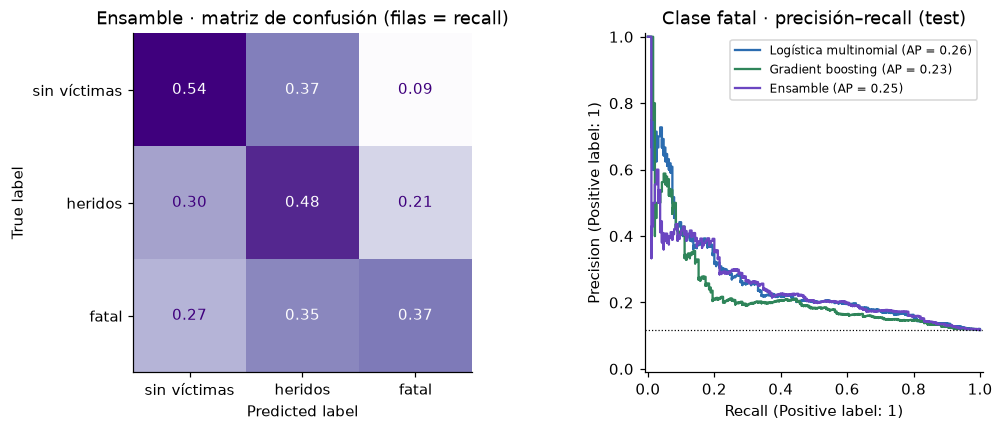

In [17]:
from sklearn.metrics import recall_score
ens2_fit = clone(ens2).fit(tr2[X2], tr2.GRAVEDAD)
proba_ens2 = ens2_fit.predict_proba(te2[X2])
proba_miembros2 = {NOMBRES[k]: m.predict_proba(te2[X2]) for k, m in ens2_fit.named_estimators_.items()}
h2 = {k: E.metricas_multiclase(te2.GRAVEDAD, v) for k, v in proba_miembros2.items()}
h2[ENS] = E.metricas_multiclase(te2.GRAVEDAD, proba_ens2)
tabla = pd.DataFrame(h2).T
tabla["recall_fatal"] = [recall_score(te2.GRAVEDAD == 2, p.argmax(1) == 2) for p in [*proba_miembros2.values(), proba_ens2]]
display(tabla.round(4))
print(classification_report(te2.GRAVEDAD, proba_ens2.argmax(1), target_names=M.CLASES_T2, digits=3))
print("Correlación entre las probabilidades de 'fatal' de los miembros en el test:")
display(pd.DataFrame({k: v[:, 2] for k, v in proba_miembros2.items()}).corr().round(3))
FILAS.append({"tarea": "2_triaje_GRAVEDAD", "modelo": ENS, "validacion": "test estratificado 80/20", **h2[ENS]})

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(te2.GRAVEDAD, proba_ens2.argmax(1), display_labels=M.CLASES_T2, normalize="true",
                                        values_format=".2f", cmap="Purples", ax=axs[0], colorbar=False)
axs[0].set_title("Ensamble · matriz de confusión (filas = recall)")
PrecisionRecallDisplay.from_predictions(te2.GRAVEDAD == 2, proba_miembros2["Baseline · Reg. logística"][:, 2], name="Logística multinomial", ax=axs[1], color="#2b6cb0")
PrecisionRecallDisplay.from_predictions(te2.GRAVEDAD == 2, proba_miembros2[GBM][:, 2], name="Gradient boosting", ax=axs[1], color="#2f855a")
PrecisionRecallDisplay.from_predictions(te2.GRAVEDAD == 2, proba_ens2[:, 2], name="Ensamble", ax=axs[1], color="#6b46c1")
axs[1].axhline((te2.GRAVEDAD == 2).mean(), color="k", ls=":", lw=0.8)
axs[1].set_title("Clase fatal · precisión–recall (test)"); axs[1].legend(fontsize=8)
guardar(fig, "modelo_18_t2_ensamble_test.png")

### 4.4 Lectura del ensamble
- **Tarea 1 · `N_ACC`:** es el **mejor modelo en la CV y en el holdout**, pero por poco. En la CV, D² 0.268 frente a
  0.267 del gradient boosting, el mejor individual (+0.001, IC −0.001 a +0.003), y a 0.256 del Poisson (+0.012, IC −0.014
  a +0.037). Le gana a la media de 28 días en los 5 pliegues (+0.050). En el holdout llega a 0.296, frente a 0.293 del
  RF, 0.292 del MLP, 0.289 del GBM y 0.277 de la media de 28 días. La ganancia es chica porque los cuatro miembros
  predicen casi lo mismo (correlación de 0.96 a 0.98 en el holdout): promediar reduce poco error cuando los errores
  coinciden. En la figura `modelo_16` se ve que en Lima sigue la subida de agosto–septiembre mejor que el GBM.
- **Tarea 1 · `HAY_FATAL`:** **sin mejora**. PR-AUC 0.135 en la CV (logística 0.133, RF 0.140; las dos diferencias con IC
  que incluye el 0) y 0.160 en el holdout (logística 0.161). Las probabilidades siguen igual de calibradas (Brier 0.060).
  Los cuatro modelos ordenan los días de forma parecida (correlación 0.91–0.96), y la señal para anticipar un día
  fatal es débil para todos.
- **Tarea 2 · `GRAVEDAD`:** el ensamble **combina en parte las dos fortalezas**. Frente a la logística, gana en
  macro-F1 (0.447 frente a 0.419; +0.028, IC +0.024 a +0.032, 25 de 25 pliegues) y mejora el log-loss (25 de 25),
  sin perder en balanced accuracy (+0.001) ni en PR-AUC de fatales (0.268 frente a 0.266, la más alta de todos los
  modelos). Frente al RF, el mejor en macro-F1, queda un poco por debajo en macro-F1 (−0.005, IC −0.009 a −0.002), pero
  ordena mejor a los fatales (+0.005, IC +0.000 a +0.009). En el test 80/20 tiene el **mejor macro-F1** (0.447;
  RF 0.445, logística 0.436) y un recall de fatales de 0.37, entre el RF (0.27) y la logística (0.51). Aquí el ensamble
  sí aporta porque las probabilidades de "fatal" de los miembros son las más distintas (correlación de 0.66 a 0.90).
- **Conclusión:** el ensamble no es la mejor opción en cada métrica, pero es la **más equilibrada**: en ninguna
  variable queda por debajo del baseline. Para el triaje es un punto medio entre el RF (más macro-F1) y la logística
  (más fatales detectados). La decisión final depende del costo de dejar pasar un fatal.
- **Nota de reproducibilidad:** los miembros RF y MLP reproducen exactamente las cifras de sus notebooks. El GBM de la
  Tarea 2 da casi las mismas probabilidades que en `04_gradient_boosting.ipynb` (log-loss 0.998 en los dos), pero en este
  entorno su macro-F1 en el test es 0.415 y no 0.427. Con 600 árboles, pequeñas diferencias numéricas entre máquinas
  (hilos de OpenMP) cambian la clase predicha de los casos cercanos a la frontera. Esto no afecta a las conclusiones del
  ensamble, que promedia probabilidades.

## 5. Resultados guardados
Se agregan las filas del MLP y del ensamble por votación a `results/metrics.csv` (mismo esquema que el baseline; si ya existían, se reemplazan).
Las referencias no se vuelven a guardar: ya las escriben `02_modelos.ipynb` y `05_binomial_negativa.ipynb`.
Configuraciones elegidas:

In [18]:
print("Tarea 1 · N_ACC:    ", config(P1))
print("Tarea 1 · HAY_FATAL:", config(P1b))
print("Tarea 2 · GRAVEDAD: ", config(P2))
f_metrics = ROOT / "results" / "metrics.csv"
nuevas = pd.DataFrame(FILAS)
previas = pd.read_csv(f_metrics)
clave = ["tarea", "modelo", "validacion"]
previas = previas[~previas.set_index(clave).index.isin(nuevas.set_index(clave).index)]   # reemplaza si ya existían
pd.concat([previas, nuevas], ignore_index=True).to_csv(f_metrics, index=False)
print(f"{len(nuevas)} filas guardadas en {f_metrics.name}")
nuevas.round(4)

Tarea 1 · N_ACC:     alpha=1.0, hidden_layer_sizes=(32, 16), max_iter=50
Tarea 1 · HAY_FATAL: alpha=1.0, hidden_layer_sizes=(8,), max_iter=150
Tarea 2 · GRAVEDAD:  alpha=0.1, hidden_layer_sizes=(32,), max_iter=30
12 filas guardadas en metrics.csv


,tarea,modelo,validacion,poisson_dev,d2_poisson,mae,rmse,pr_auc,roc_auc,brier,prevalencia,macro_f1,balanced_acc,pr_auc_fatal,log_loss
0,1_conteo_N_ACC,MLP (ajustado),CV temporal (5 pliegues),0.9588,0.2499,0.5626,0.7929,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1_conteo_N_ACC,MLP (ajustado),holdout abr-sep 2021,0.9816,0.2921,0.6061,0.8345,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1_clasificacion_HAY_FATAL,MLP (ajustado),CV temporal (5 pliegues),NaN,NaN,NaN,NaN,0.1378,0.6994,0.0542,0.0584,NaN,NaN,NaN,NaN
3,1_clasificacion_HAY_FATAL,MLP (ajustado),holdout abr-sep 2021,NaN,NaN,NaN,NaN,0.1569,0.7223,0.0604,0.0676,NaN,NaN,NaN,NaN
4,2_triaje_GRAVEDAD,MLP (ajustado),CV estratificada 5x5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.4218,0.4603,0.2542,1.0391
5,2_triaje_GRAVEDAD,MLP (ajustado),test estratificado 80/20,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.4299,0.4710,0.2451,1.0257
6,1_conteo_N_ACC,Ensamble (votación),CV temporal (5 pliegues),0.9364,0.2678,0.5608,0.7801,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,1_conteo_N_ACC,Ensamble (votación),holdout abr-sep 2021,0.9758,0.2963,0.6000,0.8355,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,1_clasificacion_HAY_FATAL,Ensamble (votación),CV temporal (5 pliegues),NaN,NaN,NaN,NaN,0.1353,0.7153,0.0536,0.0584,NaN,NaN,NaN,NaN
9,1_clasificacion_HAY_FATAL,Ensamble (votación),holdout abr-sep 2021,NaN,NaN,NaN,NaN,0.1600,0.7329,0.0600,0.0676,NaN,NaN,NaN,NaN


## Lectura
- **Tarea 1 · `N_ACC`:** resultado mixto. En la CV temporal el MLP empata con el Poisson (D² 0.250 frente a 0.256;
  −0.006, IC −0.032 a +0.019, mejor en 1 de 5 pliegues). En el holdout abr–sep 2021 es el único modelo que supera a la
  media de 28 días (0.292 frente a 0.277; Poisson 0.267, binomial negativa 0.268), y lo hace con las 5 semillas
  (0.283 ± 0.006). La figura `modelo_10` muestra por qué: tras la cuarentena sube el número de accidentes y el Poisson
  se queda corto en los departamentos grandes, mientras que el MLP sigue mejor ese nivel. Es una señal a favor de las
  interacciones no lineales, pero un solo periodo de holdout no basta: falta confirmarla con los árboles (#2).
- **Tarea 1 · `HAY_FATAL`:** sin mejora. En la CV la media es algo mayor que la de la logística (0.138 frente a 0.133),
  pero gana en 1 solo pliegue y el IC incluye el 0; en el holdout queda por debajo con todas las semillas
  (0.154–0.160 frente a 0.161).
- **Tarea 2:** el MLP no supera a la logística multinomial. Empata en macro-F1 (0.422 frente a 0.419; +0.003, IC con
  el 0), pero ordena peor a los fatales (PR-AUC 0.254 frente a 0.266, peor en 21 de 25 pliegues) y en el test queda
  por debajo con todas las semillas (0.410–0.430 frente a 0.436). Casi todas las configuraciones de la grilla quedan
  entre 0.40 y 0.42: con estas variables la red no encuentra interacciones que el modelo lineal no capture. El límite
  está en la información del registro (sin vehículo, ocupantes ni velocidad), no en la flexibilidad del modelo.
- **Frente a Emu et al. (2022):** ellos entrenan con 5.8 millones de choques y variables del vehículo y las personas;
  aquí hay 8 105 accidentes sin esas variables.
- **Semilla:** el MLP varía ±0.006 de D² y ±0.009 de macro-F1 según la inicialización, del mismo orden que sus
  diferencias con el baseline. En el ensamble por votación (§4) el MLP pesa un cuarto
  de la predicción, así que esa varianza se diluye.